# Online Retail Data Set

#### Columns description

- InvoiceNo: A unique identifier for the invoice. An invoice number shared.
across rows means that those transactions were performed in a single invoice (multiple purchases).
- StockCode: Identifier for items contained in an invoice.
- Description: Textual description of each of the stock items.
- Quantity: The quantity of the item purchased.
- InvoiceDate: Date of purchase.
- UnitPrice: Value of each item.
- CustomerID: Identifier for customer making the purchase.
- Country: Country of customer.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
from datetime import timedelta
%matplotlib inline
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import math
sns.set_theme()
import warnings
warnings.filterwarnings("ignore")

In [2]:
df_ori = pd.read_excel("Online Retail.xlsx")

In [3]:
df_ori.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
df_ori.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


For Quantity and Unit price we have negative values, this can be caused by product returns. We must avoid these values, but first we are going to look at the data

In [5]:
# df_ori = df_copy.copy()
bool_error = (df_ori['Quantity']<=0) | (df_ori['UnitPrice']<=0)
print('With Quantity negative and UnitPrice negative:', df_ori[(df_ori['Quantity']<0) & (df_ori['UnitPrice']<0)].shape[0])
print('With Quantity or UnitPrice negative or equals to zero:', df_ori[bool_error].shape[0])
print('Values errors by percentage:', str(df_ori[bool_error].shape[0]/df_ori.shape[0]*100)[:5], '%')
print('CustomerIDs with these anomalous values are:', df_ori[bool_error]['CustomerID'].unique())

With Quantity negative and UnitPrice negative: 0
With Quantity or UnitPrice negative or equals to zero: 11805
Values errors by percentage: 2.178 %
CustomerIDs with these anomalous values are: [14527. 15311. 17548. ... 12985. 15951. 16446.]


Values without customer information or with zero or negative quantity and price will be removed

In [6]:
df_ori = df_ori[~(bool_error | df_ori['CustomerID'].isnull())]

In [7]:
df_ori.info()

<class 'pandas.DataFrame'>
Index: 397884 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    397884 non-null  object        
 1   StockCode    397884 non-null  object        
 2   Description  397884 non-null  object        
 3   Quantity     397884 non-null  int64         
 4   InvoiceDate  397884 non-null  datetime64[us]
 5   UnitPrice    397884 non-null  float64       
 6   CustomerID   397884 non-null  float64       
 7   Country      397884 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 27.3+ MB


In [8]:
df_ori.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,397884.000000,397884,397884.000000,397884.000000
mean,12.988238,2011-07-10 23:41:23.511023,3.116488,15294.423453
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000
25%,2.000000,2011-04-07 11:12:00,1.250000,13969.000000
50%,6.000000,2011-07-31 14:39:00,1.950000,15159.000000
75%,12.000000,2011-10-20 14:33:00,3.750000,16795.000000
max,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000
std,179.331775,NaN,22.097877,1713.141560


In [ ]:
# check for  cancel invoice
df_ori[df_ori['InvoiceNo'].apply(lambda x: str(x).startswith("C"))]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Internal,Amount


In [9]:
stock_desc = df_ori.groupby(['StockCode','Description']).count().reset_index()
stock_desc

,StockCode,Description,InvoiceNo,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,10002,INFLATABLE POLITICAL GLOBE,49,49,49,49,49,49
1,10080,GROOVY CACTUS INFLATABLE,21,21,21,21,21,21
2,10120,DOGGY RUBBER,30,30,30,30,30,30
3,10125,MINI FUNKY DESIGN TAPES,64,64,64,64,64,64
4,10133,COLOURING PENCILS BROWN TUBE,124,124,124,124,124,124
...,...,...,...,...,...,...,...,...
3892,C2,CARRIAGE,133,133,133,133,133,133
3893,DOT,DOTCOM POSTAGE,16,16,16,16,16,16
3894,M,Manual,284,284,284,284,284,284
3895,PADS,PADS TO MATCH ALL CUSHIONS,3,3,3,3,3,3


In [10]:
stock_desc_count = stock_desc['StockCode'].value_counts().reset_index()
stock_desc_count

,StockCode,count
0,23196,4
1,23236,4
2,22776,3
3,22937,3
4,23126,3
...,...,...
3660,C2,1
3661,DOT,1
3662,M,1
3663,PADS,1


In [11]:
stock_desc_count[stock_desc_count['count']>1][:2]

,StockCode,count
0,23196,4
1,23236,4


In [12]:
df_ori[df_ori['StockCode'] == 23196]['Description'].unique()

array(['RETRO LEAVES MAGNETIC NOTEPAD',
       'RETO LEAVES MAGNETIC SHOPPING LIST',
       'LEAVES MAGNETIC  SHOPPING LIST', 'VINTAGE LEAF MAGNETIC NOTEPAD'],
      dtype=object)

In [13]:
temp = df_ori['Description'].groupby(df_ori['StockCode']).unique().apply(pd.Series)
temp = temp[0].to_dict()
df_ori['Description'] = df_ori['StockCode'].map(temp)

df_ori['CustomerID'] = df_ori['CustomerID'].astype('int32')

In [14]:
df_ori[df_ori['StockCode'] == 23196]['Description'].unique()

<StringArray>
['RETRO LEAVES MAGNETIC NOTEPAD']
Length: 1, dtype: str

## Analyze sales

- Market representation and country

In [16]:

df_ori['Internal'] = 'No'
df_ori.loc[df_ori['Country'] == 'United Kingdom', 'Internal'] = 'Yes'
fig = px.pie(df_ori, names='Internal', title='Market representation', color_discrete_sequence=px.colors.qualitative.Pastel)
fig.show()

df_ori['Amount'] = df_ori['UnitPrice']*df_ori['Quantity']
temp = pd.DataFrame(df_ori.groupby('Country')['Amount'].sum()).reset_index().sort_values(by=['Amount'], ascending=False)
fig = px.bar(temp, x='Country', y='Amount', title='Amount sales by country',  color_discrete_sequence=px.colors.qualitative.Pastel)
fig.show()

- Top Customers

In [17]:
temp = df_ori.groupby('CustomerID')[['Amount']].sum().sort_values(by=['Amount'], ascending=False)
ratio_sales_inplot = str(list(temp[:50].sum())[0] / list(temp.sum())[0] * 100)[:5] + ' %'
fig = px.bar(temp[:50].reset_index(), x='CustomerID', y='Amount', title='50 Best Customers by amount ('+ ratio_sales_inplot + ' of total amount of sales)', color_discrete_sequence=px.colors.qualitative.Pastel)
fig.update_layout(xaxis_type = 'category')
fig.show()

ratio_sales_inplot = str(list(temp[:10].sum())[0] / list(temp.sum())[0] * 100)[:5] + ' %'
fig = px.bar(temp[:10].reset_index(), x='CustomerID', y='Amount', title='10 Best Customers by amount ('+ ratio_sales_inplot + ' of total amount of sales)', color_discrete_sequence=px.colors.qualitative.Pastel)
fig.update_layout(xaxis_type = 'category')
fig.show()

temp = df_ori.groupby('CustomerID')[['Amount']].count().sort_values(by=['Amount'], ascending=False)
temp
ratio_sales_inplot = str(list(temp[:10].sum())[0] / list(temp.sum())[0] * 100)[:4] + ' %'
fig = px.bar(temp[:10].reset_index(), x='CustomerID', y='Amount', title='10 Best Customers by frecuency of sales ('+ ratio_sales_inplot + ' of total frequency of sales)', color_discrete_sequence=px.colors.qualitative.Pastel)
fig.update_layout(xaxis_type = 'category')
fig.show()

- Top products

In [18]:
temp = (
    df_ori.groupby(['StockCode', 'Description'], as_index=False)['Amount']
    .sum()
    .sort_values(by='Amount', ascending=False)
    .reset_index(drop=True)
)
ratio_sales_inplot = str(list(temp[['Amount']][:10].sum())[0] / list(temp[['Amount']].sum())[0] * 100)[:5] + ' %'
fig = px.bar(temp[:10].reset_index(), x='Description', y='Amount', title='10 best products by amount ('+ ratio_sales_inplot + ' of total amount of sales)', color_discrete_sequence=px.colors.qualitative.Pastel)
fig.update_layout(xaxis_type='category')
fig.update_traces(marker_color='rgb(246,207,113)')
fig.show()

temp = (
    df_ori.groupby(['StockCode', 'Description'], as_index=False)['Amount']
    .count()
    .rename(columns={'Amount': 'Frequency'})
    .sort_values(by='Frequency', ascending=False)
    .reset_index(drop=True)
)
ratio_sales_inplot = str(list(temp[['Frequency']][:10].sum())[0] / list(temp[['Frequency']].sum())[0] * 100)[:5] + ' %'
fig = px.bar(temp[:10].reset_index(), x='Description', y='Frequency', title='10 best products by frequency ('+ ratio_sales_inplot + ' of total frequency of sales)', color_discrete_sequence=px.colors.qualitative.Pastel)
fig.update_layout(xaxis_type='category')
fig.update_traces(marker_color='rgb(246,207,113)')
fig.show()

### Customer Segementation with RFM
We are going to use the Recency, Frequency, Monetary Model (RFM). As stated in the Wikipedia page, RFM stands for the three dimensions:

- Recency – How recently did the customer purchase?
- Frequency – How often do they purchase?
- Monetary Value – How much do they spend?
This analysis must be careful with the time window because can be biased or inaccurate if we try to span an extremely long duration.

In [19]:
valid_dates = df_ori['InvoiceDate']
max_month = valid_dates.dt.to_period("M").max()
holdout_start = (max_month - 2).to_timestamp()
holdout_end = valid_dates.max()
holdout_start,holdout_end

(Timestamp('2011-10-01 00:00:00'), Timestamp('2011-12-09 12:50:00'))

In [20]:
historical = df_ori.loc[df_ori["InvoiceDate"] < holdout_start].copy()

In [21]:
#Extract features for each customer
data_process = historical.groupby(['CustomerID']).agg({
        'InvoiceDate': lambda x: (holdout_start - x.max()).days,
        # 'InvoiceNo': 'count',
        'InvoiceNo': 'nunique',
        'Amount': 'sum'})

#renaming
data_process.columns = ['Recency', 'Frequency', 'MonetaryValue']

data_process = data_process
data_process[:3]

,Recency,Frequency,MonetaryValue
CustomerID,,,
12346,255,1,77183.60
12347,59,5,2790.86
12348,5,4,1797.24


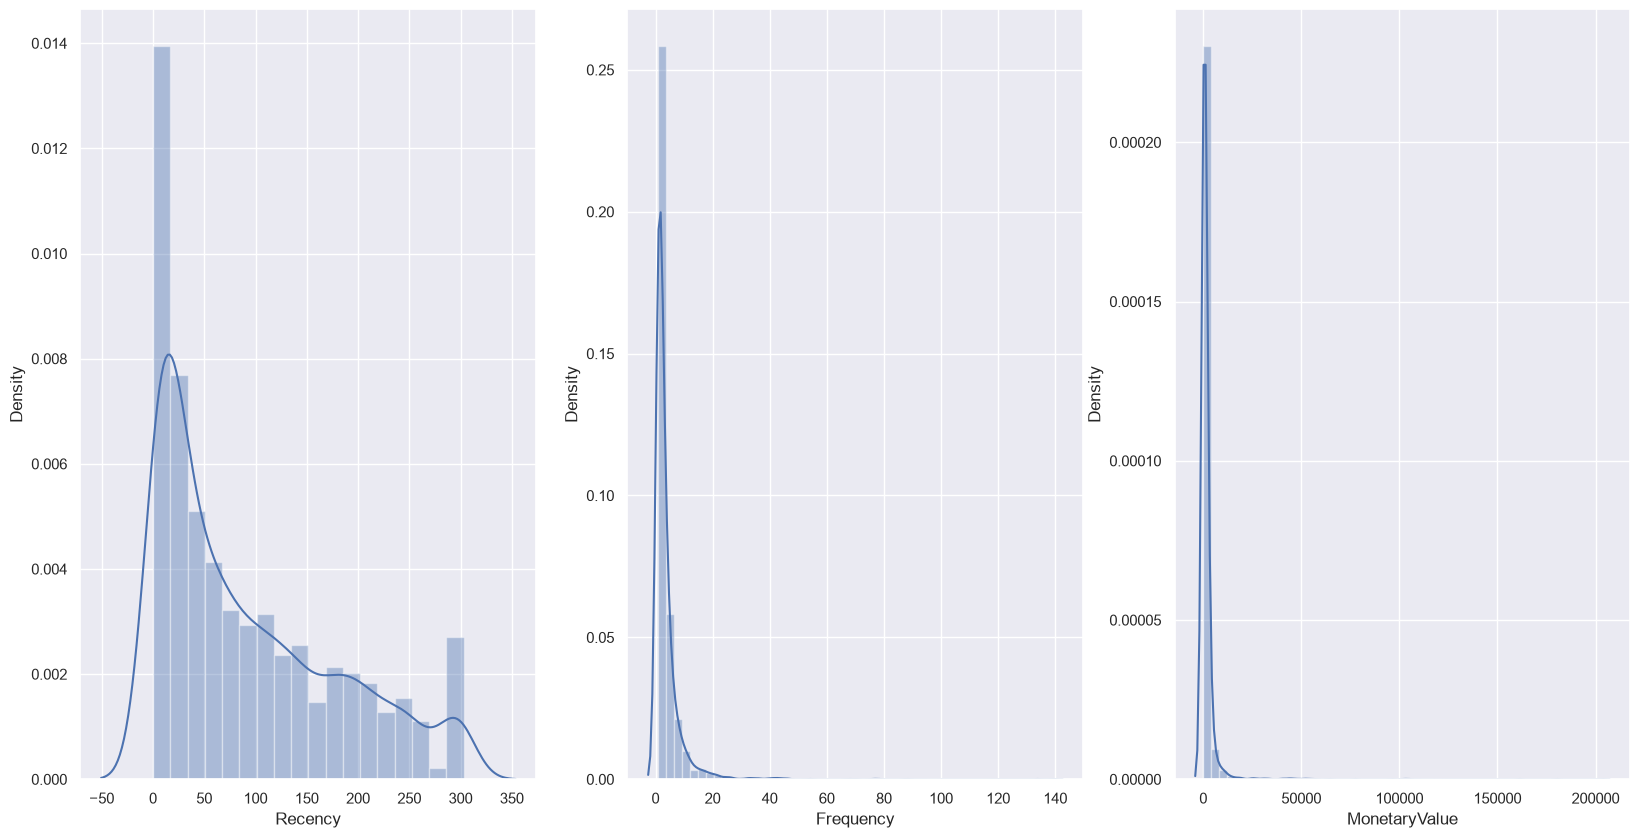

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
for i, feature in enumerate(list(data_process.columns)):
    sns.distplot(data_process[feature], ax=axes[i])

The data is skewed. Using log transformation we can improve the quality of the data for future analysis

In [23]:
data_process[data_process['Recency']==0]

,Recency,Frequency,MonetaryValue
CustomerID,,,
12583,0,11,5100.24
12676,0,5,1149.73
12694,0,2,869.67
12731,0,10,14894.65
12748,0,139,19717.39
12822,0,2,948.88
12842,0,2,1118.99
13021,0,6,1619.28
13089,0,78,46361.22


In [24]:
data_process['Recency_log'] = np.log1p(data_process['Recency'])
data_process['Frequency_log'] = np.log(data_process['Frequency'])
data_process['MonetaryValue_log'] = np.log(data_process['MonetaryValue'])
data_process[:3]

,Recency,Frequency,MonetaryValue,Recency_log,Frequency_log,MonetaryValue_log
CustomerID,,,,,,
12346,255,1,77183.60,5.545177,0.000000,11.253942
12347,59,5,2790.86,4.094345,1.609438,7.934105
12348,5,4,1797.24,1.791759,1.386294,7.494007


<Axes: xlabel='MonetaryValue_log', ylabel='Density'>

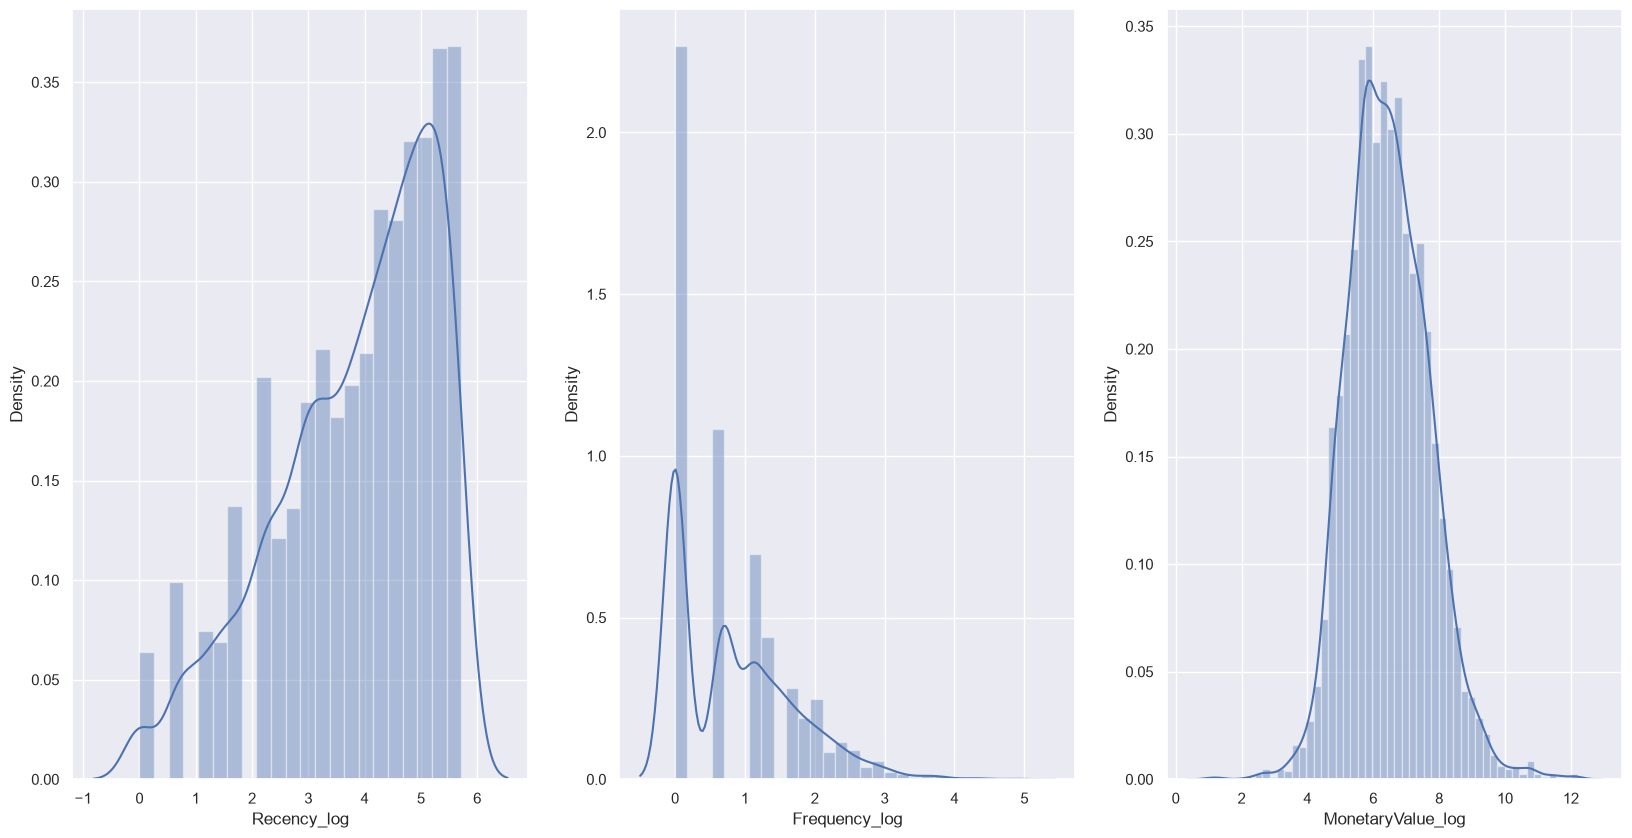

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
sns.distplot(data_process['Recency_log'], ax=axes[0])
sns.distplot(data_process['Frequency_log'], ax=axes[1])
sns.distplot(data_process['MonetaryValue_log'], ax=axes[2])


In [70]:
# import skewness
from scipy.stats import skew

print('Skewness of Recency:', skew(data_process['Recency']))
print('Skewness of Frequency:', skew(data_process['Frequency']))
print('Skewness of MonetaryValue:', skew(data_process['MonetaryValue']))

print('Skewness of Recency_log:', skew(data_process['Recency_log']))
print('Skewness of Frequency_log:', skew(data_process['Frequency_log']))
print('Skewness of MonetaryValue_log:', skew(data_process['MonetaryValue_log']))


Skewness of Recency: 0.8766699895525222
Skewness of Frequency: 9.7420165377446
Skewness of MonetaryValue: 18.145613327856736
Skewness of Recency_log: -0.7452496953002539
Skewness of Frequency_log: 0.911568673487171
Skewness of MonetaryValue_log: 0.38239176388344875


In [ ]:
# square root transformtion
print('Skewness of Recency:', skew(np.sqrt(data_process['Recency'])))
print('Skewness of Frequency:', skew(np.sqrt(data_process['Frequency'])))
print('Skewness of MonetaryValue:', skew(np.sqrt(data_process['MonetaryValue'])))

Skewness of Recency: 0.2038334759813095
Skewness of Frequency: 2.9455743919506507
Skewness of MonetaryValue: 5.674695411154543


In [ ]:
# hybrid transformtion
print('Skewness of Recency:', skew(np.sqrt(data_process['Recency'])))
print('Skewness of Frequency:', skew(np.log1p(data_process['Frequency'])))
print('Skewness of MonetaryValue:', skew(np.log1p(data_process['MonetaryValue'])))

Skewness of Recency: 0.2038334759813095
Skewness of Frequency: 1.344601606643593
Skewness of MonetaryValue: 0.3987910916773369


<Axes: xlabel='MonetaryValue_log', ylabel='Density'>

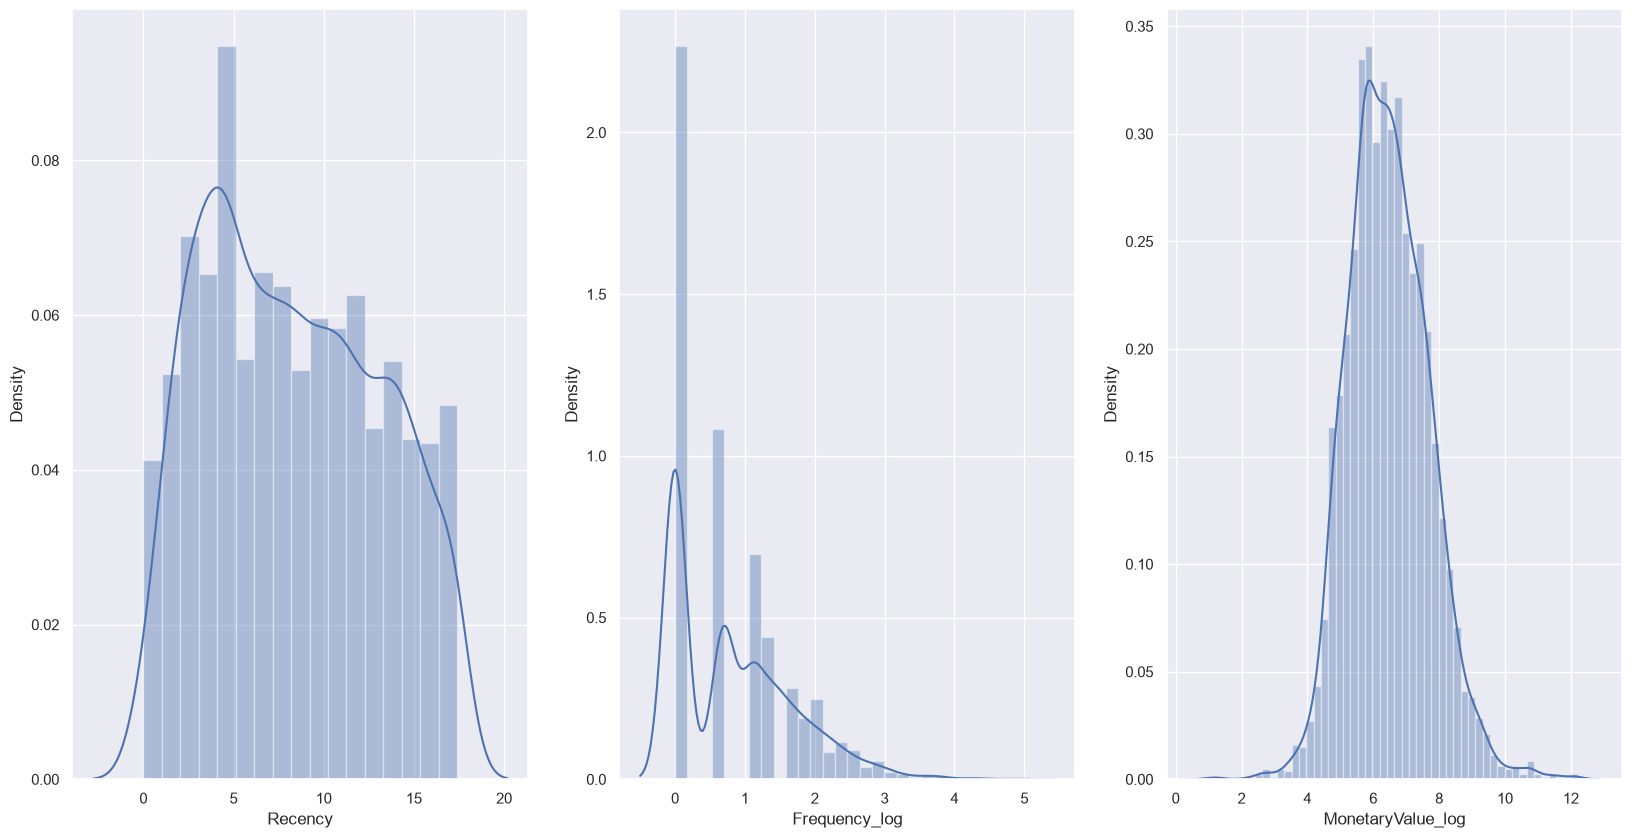

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
sns.distplot(np.sqrt(data_process['Recency']), ax=axes[0])
sns.distplot(data_process['Frequency_log'], ax=axes[1])
sns.distplot(data_process['MonetaryValue_log'], ax=axes[2])


hybrid approach (sqrt for Recency, log for Frequency & MonetaryValue) looks optimal.

Now let's normalized our data, this improves the k-means performance. We choose to use MinMaxScaler and changed the column names

In [25]:
scaler = MinMaxScaler()
#scaler = StandardScaler()
data_process_normalized = pd.DataFrame(scaler.fit_transform(data_process),index=data_process.index)
#renaming
data_process_normalized.columns = ['n_'+ i for i in data_process.columns]
data_process_normalized.describe()

,n_Recency,n_Frequency,n_MonetaryValue,n_Recency_log,n_Frequency_log,n_MonetaryValue_log
count,3616.000000,3616.000000,3616.000000,3616.000000,3616.000000,3616.000000
mean,0.303284,0.019142,0.008417,0.673133,0.166612,0.484178
std,0.286613,0.044361,0.034586,0.246878,0.173486,0.109817
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.059406,0.000000,0.001384,0.515030,0.000000,0.410904
50%,0.207921,0.007246,0.002939,0.727455,0.140470,0.477909
75%,0.488449,0.021739,0.007080,0.875271,0.280941,0.556461
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [26]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score


In [27]:
data_process_normalized.columns[3:]

Index(['n_Recency_log', 'n_Frequency_log', 'n_MonetaryValue_log'], dtype='str')

In [28]:
data_process_normalized.columns

Index(['n_Recency', 'n_Frequency', 'n_MonetaryValue', 'n_Recency_log',
       'n_Frequency_log', 'n_MonetaryValue_log'],
      dtype='str')

In [29]:
from sklearn.model_selection import train_test_split


In [41]:
SSE, max_k = [], 15
results =[]
list_input = list(data_process_normalized.columns[3:])
X= data_process_normalized[list_input]
train_X, test_X = train_test_split(X, test_size=0.2, random_state=32,shuffle=True)
for k in range(1,max_k):
    kmeans = KMeans(n_clusters=k+1, random_state=42).fit(train_X)
    SSE.append(kmeans.inertia_)
    labels = kmeans.predict(train_X)
    score = silhouette_score(train_X, labels)
    db = davies_bouldin_score(train_X, labels)
    ch = calinski_harabasz_score(train_X, labels)
    counts = pd.Series(labels).value_counts().sort_index()
    results.append({
        "k": k+1,
        "silhouette": score,
        "davies_bouldin": db,
        "calinski_harabasz": ch,
        "cluster_counts": counts.to_dict(),
        "n_small_clusters": int((counts < max(5, 0.02 * len(X))).sum()),
    })

fig = go.Figure(data=go.Scatter(x=list(range(1, max_k+1)), y=SSE, ))
fig.update_traces(marker_size=14)
fig.show()

In [42]:
pd.DataFrame(results)

,k,silhouette,davies_bouldin,calinski_harabasz,cluster_counts,n_small_clusters
0,2,0.456195,0.883501,3092.667978,"{0: 1170, 1: 1722}",0
1,3,0.427020,1.020351,2552.000205,"{0: 791, 1: 1546, 2: 555}",0
2,4,0.390503,0.907962,2628.323049,"{0: 372, 1: 1227, 2: 466, 3: 827}",0
3,5,0.356070,0.945928,2470.864396,"{0: 218, 1: 957, 2: 446, 3: 515, 4: 756}",0
4,6,0.370794,0.871296,2490.031001,"{0: 166, 1: 893, 2: 282, 3: 509, 4: 651, 5: 391}",0
5,7,0.356030,0.940311,2336.976006,"{0: 170, 1: 861, 2: 216, 3: 337, 4: 634, 5: 36...",0
6,8,0.346001,0.942165,2264.782885,"{0: 195, 1: 831, 2: 498, 3: 360, 4: 372, 5: 20...",0
7,9,0.345210,0.913149,2251.865389,"{0: 208, 1: 751, 2: 344, 3: 186, 4: 370, 5: 18...",0
8,10,0.293202,0.980278,2138.886749,"{0: 208, 1: 364, 2: 328, 3: 188, 4: 370, 5: 18...",0
9,11,0.288762,0.991467,2104.183958,"{0: 202, 1: 362, 2: 323, 3: 218, 4: 369, 5: 15...",1


In [74]:
model =  KMeans(n_clusters=2, random_state=42).fit(train_X)
train_X['cluster'] = model.predict(train_X)
fig = px.scatter_3d(train_X, x=list_input[0], y=list_input[1], z=list_input[2],
              color='cluster')
fig.show()

In [75]:
data_process_seg = data_process.copy()

In [76]:
data_process_seg.loc[train_X.index, "cluster"] = train_X["cluster"]


In [77]:
fig = px.scatter_3d(data_process_seg[data_process_seg['cluster'].notna()], x='Recency', y='Frequency', z='MonetaryValue',
              color='cluster')
fig.show()